## DRQN with GTrXL or LSTM: Droplet Protocol Tracing and Reverse Engineering

This notebook implements a Deep Recurrent Q-Network (DRQN) with support for both LSTM and Gated Transformer-XL (GTrXL) architectures for reverse-engineering droplet protocols on DMFBs. 

### Key Features:
- **LSTM**: Traditional recurrent memory for short-term dependencies
- **GTrXL**: Transformer-based memory with attention mechanism for long-term dependencies
- **Episode-based replay**: Stores complete episodes for sequential learning
- **Action masking**: Optional spatial constraint around high-reward locations

### Architecture Options:
1. **LSTM (Default)**: Fast, proven baseline with 256 hidden units
2. **GTrXL**: Attention-based memory with configurable layers, heads, and memory length

### References

```bibtex
@misc{hausknecht2017deeprecurrentqlearningpartially,
  title={Deep Recurrent Q-Learning for Partially Observable MDPs},
  author={Matthew Hausknecht and Peter Stone},
  year={2017},
  eprint={1507.06527},
  archivePrefix={arXiv},
  primaryClass={cs.LG},
  url={https://arxiv.org/abs/1507.06527},
}

@misc{parisotto2019stabilizingtransformersreinforcementlearning,
  title={Stabilizing Transformers for Reinforcement Learning}, 
  author={Emilio Parisotto and H. Francis Song and Jack W. Rae and Razvan Pascanu and Caglar Gulcehre and Siddhant M. Jayakumar and Max Jaderberg and Raphael Lopez Kaufman and Aidan Clark and Seb Noury and Matthew M. Botvinick and Nicolas Heess and Raia Hadsell},
  year={2019},
  eprint={1910.06764},
  archivePrefix={arXiv},
  primaryClass={cs.LG},
  url={https://arxiv.org/abs/1910.06764}, 
}
```

## Import necessary libraries 

In [1]:
# importing necessary libraries
import random
import time
import os 
import numpy as np
import torch
import torch.nn as nn
from collections import deque
from torch.utils.tensorboard import SummaryWriter
from tqdm import tqdm
import pickle
import json 
import matplotlib.pyplot as plt


## DRQN Agent with LSTM/GTrXL Support

**DRQNagent** is a standalone implementation supporting both LSTM and GTrXL architectures.

### Architecture
- **Feature Extractor** → **LSTM or GTrXL** → **Fully-Connected Q-value Head**
- Toggle between architectures with `use_gtrxl` parameter
- LSTM: 256 hidden units (default)
- GTrXL: Configurable layers, heads, and memory window

### Key Components
1. **Replay Buffer**: Episode-based storage (complete sequences)
2. **Network**: Conditional architecture based on `use_gtrxl` flag
3. **Training**: Standard DQN with episode sampling and target network updates

## Physics-Based Action Masking (Gradient Detachment)

**Key Innovation:** Instead of just hiding invalid actions during selection, we prevent the network from learning about them during training.

### How It Works:
1. **During Episode Collection**: Store action masks WITH each transition (obs, action, reward, next_obs, done, **mask**)
2. **During Training**: 
   - Compute Q-values for all 396 actions (architecture unchanged)
   - **Detach gradients** for invalid actions: `q_values[invalid] = q_values[invalid].detach()`
   - Mask target Q-values: `next_q_values[invalid] = -inf`
   - When `loss.backward()` runs, **gradients only flow through valid actions**

### What the Network Learns:
- **Temporal abstraction**: EMF history → velocity estimation
- **Spatial constraint**: "If droplet moving northeast, only probe northeast"
- **Physics embedding**: Invalid actions stay untrained (approach zero)

### The Goal:
Force the network to learn droplet **velocity** and **direction** from EMF gradients, not just memorize Q-values for all positions. The network learns: *"Far actions are physically impossible given trajectory."*

In [16]:
# Import custom environment and feature extractor
from Env import VoltageDistributionEnv
from CustomFeatureExtractor import CustomFeatureExtractor

class DRQNagent:

    """
    Simplified Deep Recurrent Q-Network:
    - Store complete episodes in replay buffer
    - Train LSTM on full episode sequences
    - save trained agent as .zip file to desktop 
    """
    
    def __init__(self, 
                 env,                       
                 feature_extractor, 
                 action_dim, 
                 lstm_hidden_size=256,
                 gamma=0.99, 
                 lr=1e-4, 
                 batch_size=32, 
                 buffer_size=1000,
                 epsilon_start=1.0, 
                 epsilon_end=0.05, 
                 epsilon_decay=5000,
                 target_update=500, 
                 training_steps=10_000, 
                 log_interval=50, 
                 tensorboard_dir=None,
                 run_name=None,
                 use_action_masking=False,
                 action_mask_size=5):
        
        self.env = env()
        self.feature_extractor_fn = feature_extractor
        self.action_dim = action_dim
        self.lstm_hidden_size = lstm_hidden_size
        self.gamma = gamma
        self.lr = lr
        self.batch_size = batch_size
        self.buffer_size = buffer_size
        self.epsilon_start = epsilon_start
        self.epsilon_end = epsilon_end
        self.epsilon_decay = epsilon_decay
        self.target_update = target_update
        self.training_steps = training_steps
        self.log_interval = log_interval
        self.use_action_masking = use_action_masking
        
        if action_mask_size % 2 == 0 or action_mask_size < 3:
            raise ValueError(f"action_mask_size must be an odd number >= 3, got {action_mask_size}")
        self.action_mask_size = action_mask_size
        self.action_mask_radius = action_mask_size // 2
        
        self.last_positive_reward_location = None
        self.valid_action_mask = None
        
        # running on CPU (my device is a macbook, idk use GPU if ur lucky)
        self.device = torch.device('cpu')

        # TensorBoard writer, save the train data to a chosen name (opens a folder)
        if tensorboard_dir and run_name:
            log_dir = os.path.join(tensorboard_dir, run_name)
            self.writer = SummaryWriter(log_dir=log_dir)
            print(f"TensorBoard logging to: {log_dir}")
        elif tensorboard_dir:
            self.writer = SummaryWriter(log_dir=tensorboard_dir)
            print(f"TensorBoard logging to: {tensorboard_dir}")
        else:
            self.writer = None

        # feature extractor network 
        feature_extractor = feature_extractor(self.env.observation_space)
        feat_dim = feature_extractor._features_dim
        
        # target and online networks 
        self.online_net = self._build_network(feature_extractor, feat_dim, lstm_hidden_size, action_dim)                                # online network, trained through GD
        self.target_net = self._build_network(self.feature_extractor_fn(self.env.observation_space), feat_dim, lstm_hidden_size, action_dim)    # target network
        self.target_net.load_state_dict(self.online_net.state_dict())                                                                   # copies weights/biases from online to target
        self.target_net.eval()
        
        self.optimizer = torch.optim.Adam(self.online_net.parameters(), lr=lr)
        
        # Episode replay buffer - stores complete episodes
        self.replay_buffer = deque(maxlen=buffer_size)
        
        self.step_count = 0
        self.update_count = 0
        self.episode_count = 0
        
    def _build_network(self, feat_extractor, feat_dim, hidden_size, action_dim):

        class DRQNNet(nn.Module):
            """
            Creating network for DRQN
            """
            def __init__(
                    self, 
                    feat_extractor,
                    feat_dim, 
                    hidden_size, 
                    action_dim):
                
                super().__init__()


                self.feat_extractor = feat_extractor                                # extraction layer, CNN + MLP
                self.lstm = nn.LSTM(feat_dim, hidden_size, batch_first=True)        # recurrency layer
                self.fc = nn.Sequential(                                            # Q - Net
                    nn.Linear(hidden_size, 256),
                    nn.ReLU(),
                    nn.Linear(256, action_dim)
                )

            
            def forward(self, obs_dict, hidden=None):
                # obs_dict: {key: (batch, seq_len, ...)}
                B = obs_dict[list(obs_dict.keys())[0]].shape[0]
                T = obs_dict[list(obs_dict.keys())[0]].shape[1]
                
                # Flatten to (B*T, ...)
                flat_obs = {k: v.reshape(B*T, *v.shape[2:]) for k, v in obs_dict.items()}
                features = self.feat_extractor(flat_obs)                 # (B*T, feat_dim)
                features = features.view(B, T, -1)                       # (B, T, feat_dim)
                
                lstm_out, hidden = self.lstm(features, hidden)           # (B, T, hidden_size)
                q_values = self.fc(lstm_out)                             # (B, T, action_dim)

                return q_values, hidden
        
        return DRQNNet(feat_extractor, feat_dim, hidden_size, action_dim)
    
    def get_epsilon(self):
        return self.epsilon_end + (self.epsilon_start - self.epsilon_end) * np.exp(-self.step_count / self.epsilon_decay) # epsilon decay over time steps 
    
    def select_action(self, obs_dict, hidden, epsilon):
        if random.random() < epsilon:
            if self.use_action_masking and self.valid_action_mask is not None:
                valid_actions = torch.where(self.valid_action_mask)[0].tolist()
                if len(valid_actions) > 0:
                    return random.choice(valid_actions), hidden
            return self.env.action_space.sample(), hidden 
        
        with torch.no_grad():
            obs_batch = {k: torch.from_numpy(v).unsqueeze(0).unsqueeze(0).float() 
                        for k, v in obs_dict.items()}
            q_vals, new_hidden = self.online_net(obs_batch, hidden)
            q_values = q_vals.squeeze()
            
            if self.use_action_masking and self.valid_action_mask is not None:
                masked_q = q_values.clone()
                masked_q[~self.valid_action_mask] = float('-inf')
                action = masked_q.argmax().item()
            else:
                action = q_values.argmax().item()

        return action, new_hidden
    
    def store_episode(self, episode):

        """Store complete episode: list of (obs, action, reward, next_obs, done)"""

        self.replay_buffer.append(episode)
    
    def sample_batch(self):
        if len(self.replay_buffer) < self.batch_size:
            return None
        
        # Sample random episodes
        episodes = random.sample(self.replay_buffer, self.batch_size)

        return episodes
    
    def train_step(self):
        batch = self.sample_batch()
        if batch is None:
            return None
        
        total_loss = 0
        
        for episode in batch:
          
            obs_seq = []
            action_seq = []
            reward_seq = []
            next_obs_seq = []
            done_seq = []
            mask_seq = []  # Store masks for physics-based gradient masking
            
            for transition in episode:
                # Support both old (5-tuple, no action mask) and new (6-tuple, action masked) format 
                if len(transition) == 6:
                    obs, action, reward, next_obs, done, valid_mask = transition
                    mask_seq.append(valid_mask)
                else:  # Backward compatibility
                    obs, action, reward, next_obs, done = transition
                    mask_seq.append(None)
                
                obs_seq.append(obs)
                action_seq.append(action)
                reward_seq.append(reward)
                next_obs_seq.append(next_obs)
                done_seq.append(done)
            
            # Convert to tensors - shape: (1, T, ...)
            obs_batch = {k: torch.from_numpy(np.stack([o[k] for o in obs_seq])).unsqueeze(0).float()
                        for k in obs_seq[0].keys()}
            next_obs_batch = {k: torch.from_numpy(np.stack([o[k] for o in next_obs_seq])).unsqueeze(0).float()
                             for k in next_obs_seq[0].keys()}
            
            actions = torch.LongTensor(action_seq).unsqueeze(0)     # (1, T)
            rewards = torch.FloatTensor(reward_seq).unsqueeze(0)    # (1, T)
            dones = torch.FloatTensor(done_seq).unsqueeze(0)        # (1, T)
            
            # Forward pass
            q_values, _ = self.online_net(obs_batch)        # (1, T, action_dim)
            q_values = q_values.squeeze(0)                  # (T, action_dim)
            
            # Detach gradients for invalid actions (network won't learn about them)
            for t in range(len(mask_seq)):
                if mask_seq[t] is not None:
                    invalid_mask = ~mask_seq[t]  # Invert: True = invalid actions
                    q_values[t][invalid_mask] = q_values[t][invalid_mask].detach()
            
            current_q = q_values.gather(1, actions.squeeze(0).unsqueeze(1)).squeeze(1)  # (T,)
            
            # Target Q-values
            with torch.no_grad():
                next_q_values, _ = self.target_net(next_obs_batch)          # (1, T, action_dim)
                next_q_values = next_q_values.squeeze(0)                    # (T, action_dim)
                
                # Only consider valid next actions when computing max Q
                for t in range(len(mask_seq)):
                    if mask_seq[t] is not None:
                        next_q_values[t][~mask_seq[t]] = float('-inf')
                
                max_next_q = next_q_values.max(1)[0]                        # (T,)
                target_q = rewards.squeeze(0) + self.gamma * max_next_q * (1 - dones.squeeze(0))
            
            # Loss
            loss = nn.functional.mse_loss(current_q, target_q)
            total_loss += loss.item()
            
            self.optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(self.online_net.parameters(), 10.0)
            self.optimizer.step()
        
        return total_loss / len(batch)
    
    def train(self):
        
        start_time = time.time()
        
        # Track rolling average for smoother logging
        episode_return_window = deque(maxlen=100)
        episode_normalized_return_window = deque(maxlen=100)

        
        # progress bar 
        with tqdm(total=self.training_steps, desc="Training Progress", unit="step") as pbar:

            print("\n ________________________________ training DRQN agent _________________________________\n")

            while self.step_count < self.training_steps:

                # Collect one episode
                obs, _ = self.env.reset()
                done = False
                episode = []
                episode_return = 0
                hidden = None
                episode_steps = 0
                
                while not done:
                    epsilon = self.get_epsilon()
                    action, hidden = self.select_action(obs, hidden, epsilon)
                    next_obs, reward, terminated, truncated, _ = self.env.step(action)
                    done = terminated or truncated
                    
                    # Update action mask and capture it for physics-based learning
                    if self.use_action_masking:
                        self.update_action_mask(reward, self.env._agent_location)
                        # Store a COPY of the mask with the transition
                        valid_mask = self.valid_action_mask.clone() if self.valid_action_mask is not None else None
                    else:
                        valid_mask = None
                    
                    # Store transition WITH mask (6-tuple format)
                    episode.append((obs, action, reward, next_obs, done, valid_mask))
                    episode_return += reward
                    obs = next_obs
                    self.step_count += 1
                    episode_steps += 1

                pbar.update(episode_steps)

                # Store episode
                self.store_episode(episode)
                self.episode_count += 1
                episode_return_window.append(episode_return)
                
                normalized_return = episode_return / episode_steps if episode_steps > 0 else 0
                episode_normalized_return_window.append(normalized_return)

                # Log to TensorBoard
                if self.writer:
                    self.writer.add_scalar('rollout/ep_rew_mean', np.mean(episode_return_window), self.step_count)
                    self.writer.add_scalar('rollout/ep_len_mean', episode_steps, self.step_count)
                    self.writer.add_scalar('rollout/epsilon', epsilon, self.step_count)
                    self.writer.add_scalar('train/episode_reward', episode_return, self.episode_count)
                    self.writer.add_scalar('rollout/normalized_return', normalized_return, self.episode_count)
                    self.writer.add_scalar('rollout/normalized_return_mean', np.mean(episode_normalized_return_window), self.step_count)
                
                # Train
                loss = None
                if len(self.replay_buffer) >= self.batch_size:
                    loss = self.train_step()
                    self.update_count += 1
                    
                    # Log training metrics
                    if self.writer and loss is not None:
                        self.writer.add_scalar('train/loss', loss, self.update_count)
                    
                    # Update target network
                    if self.update_count % self.target_update == 0:
                        self.target_net.load_state_dict(self.online_net.state_dict())
                
                # Log to console
                if self.episode_count % self.log_interval == 0:
                    elapsed = (time.time() - start_time) / 60
                    epsilon = self.get_epsilon()
                    mean_reward = np.mean(episode_return_window)
                    mean_normalized = np.mean(episode_normalized_return_window)
                    print(f"Episode {self.episode_count} | Steps: {self.step_count} | "
                        f"Return: {episode_return:.2f} | Mean100: {mean_reward:.2f} | "
                        f"NormReturn: {normalized_return:.3f} | MeanNorm100: {mean_normalized:.3f} | "  
                        f"Epsilon: {epsilon:.3f} | Updates: {self.update_count} | Time: {elapsed:.1f}min")
        
        # Close TensorBoard writer
        if self.writer:
            log_dir = self.writer.log_dir
            self.writer.close()
            print(f"\nTensorBoard logs saved to: {log_dir}")
            print(f"To view: tensorboard --logdir={log_dir}")
        
        print("________________ training complete _________________ \n")

    def action_masking(self, q_values, valid_actions):
        """
        Apply action masking to Q-values.
        
        Args:
            q_values: Tensor of shape (batch_size, action_dim)
            valid_actions: List of lists, each containing valid action indices for the corresponding batch element.
        Returns:
            Masked Q-values tensor.
        """
        batch_size = q_values.shape[0]
        masked_q = q_values.clone()
        
        for i in range(batch_size):
            mask = torch.ones(q_values.shape[1], dtype=torch.bool)
            if valid_actions[i] is not None and len(valid_actions[i]) > 0:
                mask[:] = False
                mask[valid_actions[i]] = True
            masked_q[i][~mask] = float('-inf')
        
        return masked_q
    
    def update_action_mask(self, reward, agent_location):
        """
        Update the valid action mask based on reward and agent location.
        Creates a square region centered at the agent location when reward > 0.
        
        Args:
            reward: The reward received
            agent_location: Current agent location as numpy array [row, col]
        """
        if not self.use_action_masking:
            self.valid_action_mask = None
            return
        
        if reward > 0:
            self.last_positive_reward_location = agent_location.copy()
            center_row, center_col = agent_location
            
            self.valid_action_mask = torch.zeros(self.action_dim, dtype=torch.bool)
            
            with open('grid_configuration.json', 'r') as f:
                config = json.load(f)
            electrode_positions = config['electrode_positions']
            
            for idx, (row, col) in enumerate(electrode_positions):
                if abs(row - center_row) <= self.action_mask_radius and abs(col - center_col) <= self.action_mask_radius:
                    self.valid_action_mask[idx] = True
        else:
            self.valid_action_mask = None 
    
    def save_complete(self, filepath):
        """
        Save complete agent (SB3-style) - can reconstruct from scratch
        Saves to .pkl file containing everything needed to rebuild agent
        """

        save_dict = {
            # Model weights
            'online_net_state_dict': self.online_net.state_dict(),
            'target_net_state_dict': self.target_net.state_dict(),
            'optimizer_state_dict': self.optimizer.state_dict(),
            
            # Training state
            'step_count': self.step_count,
            'episode_count': self.episode_count,
            'update_count': self.update_count,
            
            # Complete hyperparameters 
            'init_params': {
                'action_dim': self.action_dim,
                'lstm_hidden_size': self.lstm_hidden_size,
                'gamma': self.gamma,
                'lr': self.lr,
                'batch_size': self.batch_size,
                'buffer_size': self.buffer_size,
                'epsilon_start': self.epsilon_start,
                'epsilon_end': self.epsilon_end,
                'epsilon_decay': self.epsilon_decay,
                'target_update': self.target_update,
                'training_steps': self.training_steps,
                'log_interval': self.log_interval,
                'use_action_masking': self.use_action_masking,
                'action_mask_size': self.action_mask_size,
            },
        }
        
        # Change extension to .pkl for complete save
        if not filepath.endswith('.pkl'):
            filepath = filepath.replace('.pth', '.pkl')
        
        os.makedirs(os.path.dirname(filepath), exist_ok=True)
        
        with open(filepath, 'wb') as f:
            pickle.dump(save_dict, f)
        
        print(f"Complete agent saved to: {filepath}")
        print(f"File contains all hyperparameters - can reconstruct agent from scratch")
    
    @classmethod
    def load_complete(cls, filepath, env_constructor, feature_extractor_constructor):
        """
        Load complete agent (SB3-style) - reconstructs from saved hyperparameters
        
        Args:
            filepath: Path to .pkl file
            env_constructor: Environment constructor (lambda: YourEnv())
            feature_extractor_constructor: Feature extractor constructor (lambda obs_space: CustomFeatureExtractor(obs_space))
        
        Returns:
            Loaded agent instance
        """
        
        with open(filepath, 'rb') as f:
            save_dict = pickle.load(f)
        
        # Reconstruct agent with saved hyperparameters
        init_params = save_dict['init_params']
        agent = cls(
            env=env_constructor,
            feature_extractor=feature_extractor_constructor,
            **init_params  # saved hyperparameters used
        )
        
        # Load weights and training state
        agent.online_net.load_state_dict(save_dict['online_net_state_dict'])
        agent.target_net.load_state_dict(save_dict['target_net_state_dict'])
        agent.optimizer.load_state_dict(save_dict['optimizer_state_dict'])
        agent.step_count = save_dict['step_count']
        agent.episode_count = save_dict['episode_count']
        agent.update_count = save_dict['update_count']
        
        print(f"Complete agent loaded from: {filepath}")
        print(f"Trained for {agent.step_count} steps, {agent.episode_count} episodes")
        
        return agent

## Train Agent

Choose your architecture below. Each creates a separate agent object that can be trained independently.

**TensorBoard Logging:**
- `rollout/ep_rew_mean`: Average episode reward (last 100)
- `rollout/ep_len_mean`: Average episode length (last 100)
- `rollout/normalized_return`: Reward per step (per episode)
- `rollout/normalized_return_mean`: Average normalized return (last 100)
- `rollout/epsilon`: Exploration rate
- `train/loss`: TD loss
- `train/episode_reward`: Current episode reward

**Run TensorBoard:** `tensorboard --logdir models/DQN_tensorboard`

In [17]:
# Get action space dimension
env_instance = VoltageDistributionEnv()
action_dim = env_instance.action_space.n
print(action_dim)

70


### Option 1: Train LSTM Agent

Traditional recurrent architecture with n hidden units. 

In [ ]:
LSTMagent = DRQNagent(
    # Environment and Architecture
    env=lambda: VoltageDistributionEnv(),                              # create environment instance
    feature_extractor=lambda obs_space: CustomFeatureExtractor(obs_space),  # feature extractor 
    action_dim = action_dim,                                                    # Number of discrete actions (N x N grid) 
    lstm_hidden_size=256,                                              # LSTM hidden state dimension (memory capacity)
    
    # Training Hyperparameters
    gamma=0.99,                                                        # Discount factor (how much to value future rewards)
    lr=1e-4,                                                           # Learning rate for Adam optimizer
    batch_size=32,                                                     # Number of episodes sampled per training update
    buffer_size=1_000,                                                # Replay buffer capacity (max episodes stored)
    
    # Exploration Strategy (Epsilon-Greedy)
    epsilon_start=1.0,                                                 # Initial exploration rate (100% random actions)
    epsilon_end=0.001,                                                 # Final exploration rate (n% random, n% greedy)
    epsilon_decay=5_000,                                               # Steps over which epsilon decays exponentially
    
    # Network Updates
    target_update=250,                                                 # Frequency (in updates) to sync target network with online network
    
    # Training Schedule
    training_steps=40_000,                                             # Total environment steps to train 
    log_interval=10_000,                                               # Log training metrics every N episodes to console (tensorboard will log every step)
    
    # TensorBoard Logging
    tensorboard_dir='models/DQN_tensorboard',                          # Root directory for all TensorBoard logs
    run_name='DRQN_base_model_test_w_action_mask_5x5_adjusted',                  # Unique run identifier (creates subfolder for this experiment)
    
    # Action Masking
    use_action_masking=True,                                           # Enable/disable action masking
    action_mask_size=5                                                 # Size of action mask region (must be odd: 3, 5, 7, etc.)
)

LSTMagent.train()
LSTMagent.save_complete('models/DRQN_base_model_test_w_action_mask_5x5_adjusted.pkl')

TensorBoard logging to: models/DQN_tensorboard/DRQN_base_model_test_w_action_mask_5x5_adjusted


Training Progress:   0%|          | 0/40000 [00:00<?, ?step/s]


 ________________________________ training DRQN agent _________________________________



Training Progress:  16%|█▋        | 6549/40000 [03:06<16:04, 34.70step/s]

### Option 2: Train GTrXL Agent

Transformer-based memory with attention mechanism.

### from AI, USE WITH CAUTION - Biplove 

In [ ]:
# Import custom environment and feature extractor
from Env import VoltageDistributionEnv
from CustomFeatureExtractor import CustomFeatureExtractor
from GTrXL import StableTransformerXL

class DRQNagent:

    """
    Simplified Deep Recurrent Q-Network:
    - Store complete episodes in replay buffer
    - Train LSTM or GTrXL on full episode sequences
    - save trained agent as .zip file to desktop 
    """
    
    def __init__(self, 
                 env,                       
                 feature_extractor, 
                 action_dim, 
                 lstm_hidden_size=256,
                 gamma=0.99, 
                 lr=1e-4, 
                 batch_size=32, 
                 buffer_size=1000,
                 epsilon_start=1.0, 
                 epsilon_end=0.05, 
                 epsilon_decay=5000,
                 target_update=500, 
                 training_steps=10_000, 
                 log_interval=50, 
                 tensorboard_dir=None,
                 run_name=None,
                 use_action_masking=False,
                 action_mask_size=5,
                 use_gtrxl=False,
                 gtrxl_n_layers=2,
                 gtrxl_n_heads=4,
                 gtrxl_d_head_inner=32,
                 gtrxl_d_ff_inner=512,
                 gtrxl_mem_len=20,
                 gtrxl_dropout=0.1):
        
        self.env = env()
        self.feature_extractor_fn = feature_extractor
        self.action_dim = action_dim
        self.lstm_hidden_size = lstm_hidden_size
        self.gamma = gamma
        self.lr = lr
        self.batch_size = batch_size
        self.buffer_size = buffer_size
        self.epsilon_start = epsilon_start
        self.epsilon_end = epsilon_end
        self.epsilon_decay = epsilon_decay
        self.target_update = target_update
        self.training_steps = training_steps
        self.log_interval = log_interval
        self.use_action_masking = use_action_masking
        
        if action_mask_size % 2 == 0 or action_mask_size < 3:
            raise ValueError(f"action_mask_size must be an odd number >= 3, got {action_mask_size}")
        self.action_mask_size = action_mask_size
        self.action_mask_radius = action_mask_size // 2
        
        self.last_positive_reward_location = None
        self.valid_action_mask = None
        
        # GTrXL parameters
        self.use_gtrxl = use_gtrxl
        self.gtrxl_n_layers = gtrxl_n_layers
        self.gtrxl_n_heads = gtrxl_n_heads
        self.gtrxl_d_head_inner = gtrxl_d_head_inner
        self.gtrxl_d_ff_inner = gtrxl_d_ff_inner
        self.gtrxl_mem_len = gtrxl_mem_len
        self.gtrxl_dropout = gtrxl_dropout
        
        # running on CPU (device is a macbook)
        self.device = torch.device('cpu')

        # TensorBoard writer, save the train data to a chosen name (opens a folder)
        if tensorboard_dir and run_name:
            log_dir = os.path.join(tensorboard_dir, run_name)
            self.writer = SummaryWriter(log_dir=log_dir)
            print(f"TensorBoard logging to: {log_dir}")
        elif tensorboard_dir:
            self.writer = SummaryWriter(log_dir=tensorboard_dir)
            print(f"TensorBoard logging to: {tensorboard_dir}")
        else:
            self.writer = None

        # feature extractor network 
        feature_extractor = feature_extractor(self.env.observation_space)
        feat_dim = feature_extractor._features_dim
        
        # Build networks based on architecture choice
        self.online_net = self._build_network(feature_extractor, feat_dim, lstm_hidden_size, action_dim)
        self.target_net = self._build_network(self.feature_extractor_fn(self.env.observation_space), feat_dim, lstm_hidden_size, action_dim)
        self.target_net.load_state_dict(self.online_net.state_dict())
        self.target_net.eval()
        
        self.optimizer = torch.optim.Adam(self.online_net.parameters(), lr=lr)
        
        # Episode replay buffer - stores complete episodes
        self.replay_buffer = deque(maxlen=buffer_size)
        
        self.step_count = 0
        self.update_count = 0
        self.episode_count = 0
        
    def _build_network(self, feat_extractor, feat_dim, hidden_size, action_dim):

        if self.use_gtrxl:
            # Build GTrXL-based network
            class GTrXLNet(nn.Module):
                """
                GTrXL-based DRQN: Feature Extractor → GTrXL → Q-values
                """
                def __init__(self, feat_extractor, feat_dim, action_dim, 
                             n_layers, n_heads, d_head_inner, d_ff_inner, mem_len, dropout):
                    super().__init__()
                    self.feat_extractor = feat_extractor
                    self.use_gtrxl = True
                    
                    # GTrXL expects (T, B, d_input)
                    self.gtrxl = StableTransformerXL(
                        d_input=feat_dim,
                        n_layers=n_layers,
                        n_heads=n_heads,
                        d_head_inner=d_head_inner,
                        d_ff_inner=d_ff_inner,
                        dropout=dropout,
                        dropouta=dropout,
                        mem_len=mem_len
                    )
                    
                    # Q-value head with LayerNorm for stability
                    self.fc = nn.Sequential(
                        nn.LayerNorm(feat_dim),  # Add LayerNorm for stability
                        nn.Linear(feat_dim, 256),
                        nn.ReLU(),
                        nn.Linear(256, action_dim)
                    )
                
                def forward(self, obs_dict, memory=None):
                    # obs_dict: {key: (B, T, ...)}
                    B = obs_dict[list(obs_dict.keys())[0]].shape[0]
                    T = obs_dict[list(obs_dict.keys())[0]].shape[1]
                    
                    # Extract features: (B, T, ...) → (B*T, ...) → (B*T, feat_dim)
                    flat_obs = {k: v.reshape(B*T, *v.shape[2:]) for k, v in obs_dict.items()}
                    features = self.feat_extractor(flat_obs)
                    features = features.view(B, T, -1)
                    
                    # Transpose to (T, B, feat_dim) for GTrXL
                    features_transposed = features.transpose(0, 1)
                    
                    # Initialize memory if None
                    if memory is None:
                        memory = self.gtrxl.init_memory(device=features.device)
                    
                    # GTrXL forward pass
                    gtrxl_out = self.gtrxl(features_transposed, memory)
                    logits = gtrxl_out["logits"]
                    new_memory = gtrxl_out["memory"]
                    
                    # Transpose back to (B, T, feat_dim)
                    logits = logits.transpose(0, 1)
                    
                    # Compute Q-values
                    q_values = self.fc(logits)
                    
                    return q_values, new_memory
            
            return GTrXLNet(feat_extractor, feat_dim, action_dim,
                           self.gtrxl_n_layers, self.gtrxl_n_heads, 
                           self.gtrxl_d_head_inner, self.gtrxl_d_ff_inner,
                           self.gtrxl_mem_len, self.gtrxl_dropout)
        
        else:
            # Build LSTM-based network 
            class DRQNNet(nn.Module):
                """
                Creating network for DRQN with LSTM
                """
                def __init__(self, feat_extractor, feat_dim, hidden_size, action_dim):
                    super().__init__()
                    self.feat_extractor = feat_extractor
                    self.use_gtrxl = False
                    self.lstm = nn.LSTM(feat_dim, hidden_size, batch_first=True)
                    self.fc = nn.Sequential(
                        nn.Linear(hidden_size, 256),
                        nn.ReLU(),
                        nn.Linear(256, action_dim)
                    )

                def forward(self, obs_dict, hidden=None):
                    # obs_dict: {key: (batch, seq_len, ...)}
                    B = obs_dict[list(obs_dict.keys())[0]].shape[0]
                    T = obs_dict[list(obs_dict.keys())[0]].shape[1]
                    
                    # Flatten to (B*T, ...)
                    flat_obs = {k: v.reshape(B*T, *v.shape[2:]) for k, v in obs_dict.items()}
                    features = self.feat_extractor(flat_obs)  # (B*T, feat_dim)
                    features = features.view(B, T, -1)  # (B, T, feat_dim)
                    
                    lstm_out, hidden = self.lstm(features, hidden)  # (B, T, hidden_size)
                    q_values = self.fc(lstm_out)  # (B, T, action_dim)

                    return q_values, hidden
            
            return DRQNNet(feat_extractor, feat_dim, hidden_size, action_dim)
    
    def get_epsilon(self):
        return self.epsilon_end + (self.epsilon_start - self.epsilon_end) * np.exp(-self.step_count / self.epsilon_decay)
    
    def select_action(self, obs_dict, hidden, epsilon):
        if random.random() < epsilon:
            if self.use_action_masking and self.valid_action_mask is not None:
                valid_actions = torch.where(self.valid_action_mask)[0].tolist()
                if len(valid_actions) > 0:
                    return random.choice(valid_actions), hidden
            return self.env.action_space.sample(), hidden 
        
        with torch.no_grad():
            obs_batch = {k: torch.from_numpy(v).unsqueeze(0).unsqueeze(0).float() 
                        for k, v in obs_dict.items()}
            q_vals, new_hidden = self.online_net(obs_batch, hidden)
            q_values = q_vals.squeeze()
            
            if self.use_action_masking and self.valid_action_mask is not None:
                masked_q = q_values.clone()
                masked_q[~self.valid_action_mask] = float('-inf')
                action = masked_q.argmax().item()
            else:
                action = q_values.argmax().item()

        return action, new_hidden
    
    def store_episode(self, episode):
        """Store complete episode: list of (obs, action, reward, next_obs, done)"""
        self.replay_buffer.append(episode)
    
    def sample_batch(self):
        if len(self.replay_buffer) < self.batch_size:
            return None
        
        # Sample random episodes
        episodes = random.sample(self.replay_buffer, self.batch_size)
        return episodes
    
    def train_step(self):
        batch = self.sample_batch()
        if batch is None:
            return None
        
        total_loss = 0
        
        for episode in batch:
            # Unpack episode
            obs_seq = []
            action_seq = []
            reward_seq = []
            next_obs_seq = []
            done_seq = []
            
            for transition in episode:
                obs, action, reward, next_obs, done = transition
                obs_seq.append(obs)
                action_seq.append(action)
                reward_seq.append(reward)
                next_obs_seq.append(next_obs)
                done_seq.append(done)
            
            # Convert to tensors - shape: (1, T, ...)
            obs_batch = {k: torch.from_numpy(np.stack([o[k] for o in obs_seq])).unsqueeze(0).float()
                        for k in obs_seq[0].keys()}
            next_obs_batch = {k: torch.from_numpy(np.stack([o[k] for o in next_obs_seq])).unsqueeze(0).float()
                             for k in next_obs_seq[0].keys()}
            
            actions = torch.LongTensor(action_seq).unsqueeze(0)     # (1, T)
            rewards = torch.FloatTensor(reward_seq).unsqueeze(0)    # (1, T)
            dones = torch.FloatTensor(done_seq).unsqueeze(0)        # (1, T)
            
            # Forward pass
            q_values, _ = self.online_net(obs_batch)        # (1, T, action_dim)
            q_values = q_values.squeeze(0)                  # (T, action_dim).  
            current_q = q_values.gather(1, actions.squeeze(0).unsqueeze(1)).squeeze(1)  # (T,)
            
            # Target Q-values
            with torch.no_grad():
                next_q_values, _ = self.target_net(next_obs_batch)          # (1, T, action_dim)
                next_q_values = next_q_values.squeeze(0)                    # (T, action_dim)
                max_next_q = next_q_values.max(1)[0]                        # (T,)
                target_q = rewards.squeeze(0) + self.gamma * max_next_q * (1 - dones.squeeze(0))
            
            # Loss
            loss = nn.functional.mse_loss(current_q, target_q)
            total_loss += loss.item()
            
            # Optimize
            self.optimizer.zero_grad()
            loss.backward()
            # Use gentler gradient clipping for GTrXL
            clip_value = 1.0 if self.use_gtrxl else 10.0
            nn.utils.clip_grad_norm_(self.online_net.parameters(), clip_value)
            self.optimizer.step()
        
        return total_loss / len(batch)
    
    def train(self):
        """
        Main training loop: collect episodes and train on replay buffer
        """
        episode_rewards = []
        episode_lengths = []
        
        pbar = tqdm(total=self.training_steps, desc="Training DRQN")
        
        # For tracking running statistics
        recent_rewards = deque(maxlen=100)
        recent_lengths = deque(maxlen=100)
        recent_normalized = deque(maxlen=100)
        last_print_step = 0
        
        while self.step_count < self.training_steps:
            # Collect one episode
            obs, _ = self.env.reset()
            episode = []
            episode_reward = 0
            episode_length = 0
            done = False
            truncated = False
            
            # Initialize hidden state based on architecture
            if self.use_gtrxl:
                hidden = self.online_net.gtrxl.init_memory(device=self.device)
            else:
                hidden = None
            
            while not (done or truncated):
                epsilon = self.get_epsilon()
                action, hidden = self.select_action(obs, hidden, epsilon)
                
                next_obs, reward, done, truncated, info = self.env.step(action)
                
                # Update action mask if positive reward received
                if self.use_action_masking and reward > 0:
                    probe_pos = self.env._agent_location
                    self.update_action_mask(probe_pos)
                
                episode.append((obs, action, reward, next_obs, done))
                episode_reward += reward
                episode_length += 1
                
                obs = next_obs
                self.step_count += 1
                pbar.update(1)
                
                if self.step_count >= self.training_steps:
                    break
            
            # Reset action mask at episode end
            if self.use_action_masking:
                self.valid_action_mask = None
                self.last_positive_reward_location = None
            
            # Store episode and train
            self.store_episode(episode)
            episode_rewards.append(episode_reward)
            episode_lengths.append(episode_length)
            self.episode_count += 1
            
            # Update running statistics
            recent_rewards.append(episode_reward)
            recent_lengths.append(episode_length)
            normalized_return = episode_reward / episode_length if episode_length > 0 else 0
            recent_normalized.append(normalized_return)
            
            # Print progress more frequently (every 500 steps instead of 100 episodes)
            if self.step_count - last_print_step >= 500:
                avg_reward = np.mean(recent_rewards)
                avg_length = np.mean(recent_lengths)
                avg_norm = np.mean(recent_normalized)
                arch_name = "GTrXL" if self.use_gtrxl else "LSTM"
                print(f"\n[{arch_name}] Steps: {self.step_count:5d} | Episodes: {self.episode_count:4d} | "
                      f"AvgRew: {avg_reward:6.2f} | AvgLen: {avg_length:5.1f} | "
                      f"NormRet: {avg_norm:.3f} | ε: {self.get_epsilon():.3f}")
                last_print_step = self.step_count
            
            # Log per-episode metrics to TensorBoard (matching LSTM format)
            if self.writer:
                # Calculate normalized return (reward per step)
                normalized_return = episode_reward / episode_length if episode_length > 0 else 0
                
                # rollout/normalized_return (per episode, raw) - use step_count for x-axis
                self.writer.add_scalar('rollout/normalized_return', normalized_return, self.step_count)
                
                # rollout/epsilon
                self.writer.add_scalar('rollout/epsilon', self.get_epsilon(), self.step_count)
                
                # Rolling averages - use step_count for consistent x-axis
                if len(episode_rewards) >= 100:
                    avg_reward = np.mean(episode_rewards[-100:])
                    avg_length = np.mean(episode_lengths[-100:])
                    avg_norm = np.mean([r/l if l > 0 else 0 for r, l in zip(episode_rewards[-100:], episode_lengths[-100:])])
                    
                    # rollout/ep_rew_mean
                    self.writer.add_scalar('rollout/ep_rew_mean', avg_reward, self.step_count)
                    # rollout/ep_len_mean
                    self.writer.add_scalar('rollout/ep_len_mean', avg_length, self.step_count)
                    # rollout/normalized_return_mean
                    self.writer.add_scalar('rollout/normalized_return_mean', avg_norm, self.step_count)
            
            # Train on replay buffer
            if len(self.replay_buffer) >= self.batch_size:
                loss = self.train_step()
                if loss is not None:
                    self.update_count += 1
                    
                    # Log training metrics to TensorBoard - use step_count for consistent x-axis
                    if self.writer:
                        # train/loss
                        self.writer.add_scalar('train/loss', loss, self.step_count)
                        # train/episode_reward (current episode)
                        self.writer.add_scalar('train/episode_reward', episode_reward, self.step_count)
            
            # Update target network
            if self.update_count % self.target_update == 0 and self.update_count > 0:
                self.target_net.load_state_dict(self.online_net.state_dict())
                if self.writer:
                    self.writer.add_scalar('Target_Update', self.update_count, self.step_count)
        
        pbar.close()
        print(f"\n{'='*80}")
        print(f"Training complete! Total episodes: {self.episode_count}")
        print(f"Average reward (last 100 episodes): {np.mean(episode_rewards[-100:]):.2f}")
        print(f"Average normalized return (last 100 episodes): {np.mean([r/l for r, l in zip(episode_rewards[-100:], episode_lengths[-100:])]):.3f}")
        print(f"{'='*80}\n")
        
        return episode_rewards, episode_lengths
    
    def update_action_mask(self, center_pos):
        """
        Create action mask centered at probe position with configurable radius.
        Args:
            center_pos: (row, col) position to center the mask
        """
        self.last_positive_reward_location = center_pos
        
        # Load grid configuration
        with open('grid_configuration.json', 'r') as f:
            config = json.load(f)
        
        electrode_positions = config['electrode_positions']
        
        # Create mask: True = valid action
        self.valid_action_mask = torch.zeros(self.action_dim, dtype=torch.bool)
        
        center_row, center_col = center_pos
        
        for action_idx, pos in enumerate(electrode_positions):
            row, col = pos
            # Check if within mask radius
            distance = abs(row - center_row) + abs(col - center_col)  # Manhattan
            
            if distance <= self.action_mask_radius:
                self.valid_action_mask[action_idx] = True
        
        # Ensure at least one action is valid
        if not self.valid_action_mask.any():
            self.valid_action_mask = None
    
    def save_complete(self, filepath):
        """
        Save complete agent state including networks, optimizer, and hyperparameters
        """
        save_dict = {
            'online_net_state': self.online_net.state_dict(),
            'target_net_state': self.target_net.state_dict(),
            'optimizer_state': self.optimizer.state_dict(),
            'step_count': self.step_count,
            'update_count': self.update_count,
            'episode_count': self.episode_count,
            'init_params': {
                'action_dim': self.action_dim,
                'lstm_hidden_size': self.lstm_hidden_size,
                'gamma': self.gamma,
                'lr': self.lr,
                'batch_size': self.batch_size,
                'buffer_size': self.buffer_size,
                'epsilon_start': self.epsilon_start,
                'epsilon_end': self.epsilon_end,
                'epsilon_decay': self.epsilon_decay,
                'target_update': self.target_update,
                'use_action_masking': self.use_action_masking,
                'action_mask_size': self.action_mask_size,
                'use_gtrxl': self.use_gtrxl,
                'gtrxl_n_layers': self.gtrxl_n_layers,
                'gtrxl_n_heads': self.gtrxl_n_heads,
                'gtrxl_d_head_inner': self.gtrxl_d_head_inner,
                'gtrxl_d_ff_inner': self.gtrxl_d_ff_inner,
                'gtrxl_mem_len': self.gtrxl_mem_len,
                'gtrxl_dropout': self.gtrxl_dropout,
            }
        }
        
        with open(filepath, 'wb') as f:
            pickle.dump(save_dict, f)
        
        print(f"Agent saved to {filepath}")
    
    @classmethod
    def load_complete(cls, filepath, env, feature_extractor, tensorboard_dir=None, run_name=None):
        """
        Load complete agent state from file
        """
        with open(filepath, 'rb') as f:
            save_dict = pickle.load(f)
        
        # Reconstruct agent with saved hyperparameters
        params = save_dict['init_params']
        agent = cls(
            env=env,
            feature_extractor=feature_extractor,
            action_dim=params['action_dim'],
            lstm_hidden_size=params['lstm_hidden_size'],
            gamma=params['gamma'],
            lr=params['lr'],
            batch_size=params['batch_size'],
            buffer_size=params['buffer_size'],
            epsilon_start=params['epsilon_start'],
            epsilon_end=params['epsilon_end'],
            epsilon_decay=params['epsilon_decay'],
            target_update=params['target_update'],
            tensorboard_dir=tensorboard_dir,
            run_name=run_name,
            use_action_masking=params.get('use_action_masking', False),
            action_mask_size=params.get('action_mask_size', 5),
            use_gtrxl=params.get('use_gtrxl', False),
            gtrxl_n_layers=params.get('gtrxl_n_layers', 2),
            gtrxl_n_heads=params.get('gtrxl_n_heads', 4),
            gtrxl_d_head_inner=params.get('gtrxl_d_head_inner', 32),
            gtrxl_d_ff_inner=params.get('gtrxl_d_ff_inner', 512),
            gtrxl_mem_len=params.get('gtrxl_mem_len', 20),
            gtrxl_dropout=params.get('gtrxl_dropout', 0.1),
        )
        
        # Load network and optimizer states
        agent.online_net.load_state_dict(save_dict['online_net_state'])
        agent.target_net.load_state_dict(save_dict['target_net_state'])
        agent.optimizer.load_state_dict(save_dict['optimizer_state'])
        agent.step_count = save_dict['step_count']
        agent.update_count = save_dict['update_count']
        agent.episode_count = save_dict['episode_count']
        
        arch_name = 'GTrXL' if agent.use_gtrxl else 'LSTM'
        print(f"Loaded {arch_name} agent from {filepath}")
        print(f"Training state: {agent.episode_count} episodes, {agent.step_count} steps")
        
        return agent


In [14]:
GTrXL_agent = DRQNagent(
    env=lambda: VoltageDistributionEnv(),
    feature_extractor=lambda obs_space: CustomFeatureExtractor(obs_space),
    action_dim=action_dim,
    
    # GTrXL Architecture (Optimized hyperparameters)
    use_gtrxl=True,
    gtrxl_n_layers=2,
    gtrxl_n_heads=4,
    gtrxl_d_head_inner=32,
    gtrxl_d_ff_inner=256,  # Reduced from 512 for faster learning
    gtrxl_mem_len=15,      # Reduced from 25 for better credit assignment
    gtrxl_dropout=0.05,    # Reduced from 0.1 to reduce regularization
    
    # Training Parameters (Optimized for GTrXL)
    gamma=0.99,
    lr=5e-5,              # Lower LR for transformer stability (was 1e-4)
    batch_size=16,        # Smaller batch for better gradient signal (was 32)
    buffer_size=1_000,
    epsilon_start=1.0,
    epsilon_end=0.001,
    epsilon_decay=5_000,
    target_update=100,    # More frequent target updates (was 250)
    training_steps=40_000,
    
    # Logging
    tensorboard_dir='models/DQN_tensorboard',
    run_name='GTrXL_DRQN_40k_optimized',
    
    # Optional: Action Masking
    use_action_masking=False,
    action_mask_size=3
)

print("=" * 80)
print("GTrXL Agent Configuration:")
print("-" * 80)
print(f"  Architecture: GTrXL ({GTrXL_agent.gtrxl_n_layers} layers, {GTrXL_agent.gtrxl_n_heads} heads)")
print(f"  Memory Length: {GTrXL_agent.gtrxl_mem_len}")
print(f"  Learning Rate: {GTrXL_agent.lr:.2e} (Lower than LSTM for stability)")
print(f"  Batch Size: {GTrXL_agent.batch_size} (Smaller for better gradients)")
print(f"  Target Update: Every {GTrXL_agent.target_update} updates")
print(f"  Gradient Clipping: 1.0 (Gentler for transformers)")
print("=" * 80)
print()

rewards, lengths = GTrXL_agent.train()
GTrXL_agent.save_complete('models/GTrXL_DRQN_40k_optimized.pkl')

TensorBoard logging to: models/DQN_tensorboard/GTrXL_DRQN_40k_optimized
GTrXL Agent Configuration:
--------------------------------------------------------------------------------
  Architecture: GTrXL (2 layers, 4 heads)
  Memory Length: 15
  Learning Rate: 5.00e-05 (Lower than LSTM for stability)
  Batch Size: 16 (Smaller for better gradients)
  Target Update: Every 100 updates
  Gradient Clipping: 1.0 (Gentler for transformers)



Training DRQN:   1%|          | 494/40000 [00:09<19:03, 34.54it/s] 


[GTrXL] Steps:   503 | Episodes:   51 | AvgRew:   0.21 | AvgLen:   9.9 | NormRet: 0.024 | ε: 0.904


Training DRQN:   2%|▎         | 1000/40000 [00:22<19:16, 33.73it/s]


[GTrXL] Steps:  1006 | Episodes:  100 | AvgRew:   0.28 | AvgLen:  10.1 | NormRet: 0.029 | ε: 0.818


Training DRQN:   4%|▍         | 1500/40000 [00:36<15:07, 42.42it/s]

... (151 outputs left out)

Training DRQN: 100%|█████████▉| 39877/40000 [20:43<00:03, 31.25it/s]


[GTrXL] Steps: 39892 | Episodes: 4011 | AvgRew:   0.97 | AvgLen:  10.5 | NormRet: 0.098 | ε: 0.001


Training DRQN: 100%|██████████| 40000/40000 [20:46<00:00, 32.08it/s]




Training complete! Total episodes: 4021
Average reward (last 100 episodes): 0.97
Average normalized return (last 100 episodes): 0.098

Agent saved to models/GTrXL_DRQN_40k_optimized.pkl
Agent saved to models/GTrXL_DRQN_40k_optimized.pkl


### Training Monitoring Tips

**Console Output:** Now prints every 500 steps (instead of every 100 episodes) with format:
```
[GTrXL] Steps: 1000 | Episodes: 45 | AvgRew: 5.23 | AvgLen: 22.1 | NormRet: 0.236 | ε: 0.819
```

**TensorBoard Metrics to Watch:**
- `rollout/normalized_return_mean`: Should increase over time (target: ~0.8+)
- `train/loss`: Should decrease and stabilize
- `rollout/epsilon`: Exponential decay to 0.001

**Signs of Good Learning:**
- Normalized return steadily increasing
- Episode length decreasing (agent finding droplet faster)
- Loss stabilizing after initial volatility

**Signs of Poor Learning (GTrXL):**
- Flat normalized return after 10k steps → LR too low or memory too long
- Exploding loss → LR too high or gradient clipping too loose
- Oscillating performance → Target update frequency issue

In [ ]:
# Quick hyperparameter comparison helper
def print_architecture_comparison():
    """Compare LSTM vs GTrXL hyperparameters"""
    print("\n" + "=" * 80)
    print("ARCHITECTURE COMPARISON: LSTM vs GTrXL")
    print("=" * 80)
    print(f"{'Parameter':<25} {'LSTM':<25} {'GTrXL (Optimized)':<25}")
    print("-" * 80)
    print(f"{'Learning Rate':<25} {'1e-4':<25} {'5e-5 (50% lower)':<25}")
    print(f"{'Batch Size':<25} {'32':<25} {'16 (50% smaller)':<25}")
    print(f"{'Target Update Freq':<25} {'250':<25} {'100 (2.5x more frequent)':<25}")
    print(f"{'Gradient Clipping':<25} {'10.0':<25} {'1.0 (10x gentler)':<25}")
    print(f"{'Memory/Hidden Units':<25} {'256':<25} {'mem_len=15':<25}")
    print(f"{'Architecture Specific':<25} {'Simple LSTM':<25} {'2L-4H Transformer+LN':<25}")
    print(f"{'Dropout':<25} {'N/A':<25} {'0.05':<25}")
    print("=" * 80)
    print("\nKey Insight: Transformers need gentler optimization and more frequent updates")
    print("=" * 80 + "\n")

# Run to see comparison
print_architecture_comparison()

## Test and Visualize Trained Agent

Load a trained model and visualize Q-values and agent behavior in the environment.

In [21]:
with open('grid_configuration.json', 'r') as f:
    config = json.load(f)

# Access values
electrode_positions = config['electrode_positions']
grid_size = config['gridSize']
obstacles = config['obstacles']

%matplotlib inline
def extract_qvalues(model, obs_dict, hidden=None):

    """Extract Q-values for given observation using the trained model"""
    
    with torch.no_grad():
        obs_batch = {k: torch.from_numpy(v).unsqueeze(0).unsqueeze(0).float() 
                     for k, v in obs_dict.items()}
        q_vals, new_hidden = model.online_net(obs_batch, hidden)
        q_values = q_vals.squeeze()
        
        if model.use_action_masking and model.valid_action_mask is not None:
            q_values_masked = q_values.clone()
            q_values_masked[~model.valid_action_mask] = float('-inf')
            return q_values_masked.cpu().numpy(), new_hidden
        
        return q_values.cpu().numpy(), new_hidden

def plot_qvalues_heatmap(q_values, model=None):

    """Plot heatmap of Q-values over the action grid."""

    plt.figure(figsize=(10, 8))
    q_grid = np.full((grid_size, grid_size), np.nan)

    for idx, (row, col) in enumerate(electrode_positions):
        q_grid[row, col] = q_values[idx]  
        
    max_q_idx = np.argmax(q_values)
    max_row, max_col = electrode_positions[max_q_idx]

    plt.imshow(q_grid, cmap='viridis', interpolation='nearest', origin = 'upper')
    plt.colorbar(label='Q-value')
    rect = plt.Rectangle((max_col - 0.5, max_row - 0.5), 1, 1, linewidth=3, edgecolor='red', facecolor='none')
    plt.gca().add_patch(rect)
    
    title = 'Q-values Heatmap over Action Space'
    if model is not None and model.use_action_masking:
        mask_size = model.action_mask_size
        title += f' (Action Mask: {mask_size}x{mask_size})'
    
    plt.title(title)
    plt.xlabel('X Position')
    plt.ylabel('Y Position')
    plt.show(0.1)

def main(model_path, episodes, render_delay): 
    """main renderer loop for trained agent"""
    
    from IPython.display import clear_output
    env = VoltageDistributionEnv(render_mode='human')
    
    episode_summaries = []
    
    for ep in range(episodes):
        obs, _ = env.reset()
        done = False
        hidden = None
        total_reward = 0
        step_num = 0
        
        model_path.valid_action_mask = None
        
        while not done:
            clear_output(wait=True)
            
            q_values, hidden = extract_qvalues(model_path, obs, hidden)
            max_q_idx = np.argmax(q_values)
            
            action = max_q_idx
            
            next_obs, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
            
            if model_path.use_action_masking:
                model_path.update_action_mask(reward, env._agent_location)
            
            env.render()
            plot_qvalues_heatmap(q_values, model_path)
            
            time.sleep(render_delay)
            
            total_reward += reward
            obs = next_obs
            step_num += 1
        
        summary = f"Episode {ep+1} | Total Reward: {total_reward:.2f} | Steps: {len(env._droplet_path)}"
        episode_summaries.append(summary)
    
    for entry in episode_summaries:
        print(entry)
    
    env.close()
    plt.close()

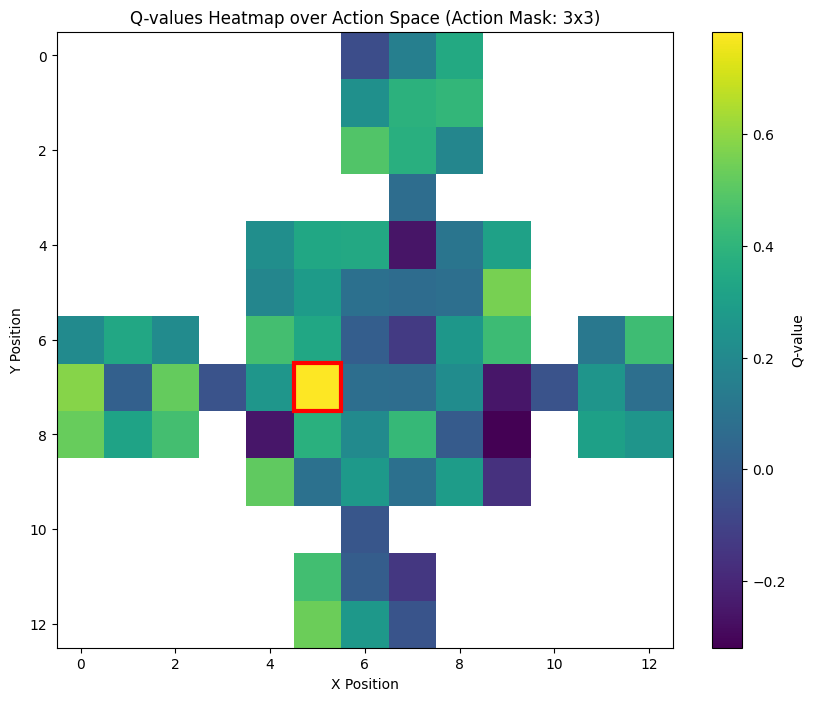

KeyboardInterrupt: 

In [22]:
# Load trained agent
loaded_agent = DRQNagent.load_complete(
    'models/GTrXL_DRQN_40k.pkl',  # Change to your model path
    env=VoltageDistributionEnv,
    feature_extractor=CustomFeatureExtractor
)

# Run visualization
main(loaded_agent, episodes=5, render_delay=0.5)

## Cross-Episode Learning (online learning)

Online learning where the agent **improves performance through repeated execution** of the same protocol.

**Approach**: 
- Generate a random 10-step protocol
- Execute multiple episodes on this same protocol
- After each episode, train intensively on accumulated experience
- Agent learns to optimize its policy for this specific protocol

**Key Mechanism - Frozen Foundation Buffer**:
- Episodes 1-3 are stored as "foundation" and never evicted
- Episodes 4+ are stored in a sliding window (most recent 5)
- Training samples 70% from foundation, 30% from recent episodes
- This prevents catastrophic forgetting while allowing adaptation

In [16]:
import matplotlib.pyplot as plt
from Env import VoltageDistributionEnv, voltage_grid, get_obs


def finetune_on_length_10(agent, training_steps=20_000, run_name='DRQN_finetuned_length10'):

    """
    Fine-tune with exploration and learning rate reset.
    """

    original_step_count = agent.step_count
    agent.step_count = 0  # Reset step count to restart epsilon schedule
    agent.epsilon_start = 0.3  # Moderate exploration
    agent.epsilon_end = 0.01   # Lower than training, higher than 0.001
    agent.epsilon_decay = 3000  # Decay over fine-tuning period
    
    print(f"Reset exploration: ε starts at {agent.epsilon_start}, decays to {agent.epsilon_end}")
    print(f"Original training: {original_step_count} steps completed\n")
    
    
    # Setup TensorBoard
    if run_name:
        log_dir = os.path.join('models/DQN_tensorboard', run_name)
        agent.writer = SummaryWriter(log_dir=log_dir)
        print(f"TensorBoard logging to: {log_dir}\n")
    
    target_steps = training_steps
    
    # reset
    original_reset = agent.env.reset
    def reset_length_10():
        obs, info = original_reset()
        while agent.env.length != 10:
            obs, info = original_reset()
        return obs, info
    
    agent.env.reset = reset_length_10
    
    # Training loop
    start_time = time.time()
    episode_return_window = deque(maxlen=100)
    episode_normalized_return_window = deque(maxlen=100)
    
    with tqdm(total=training_steps, desc="Fine-Tuning Progress", unit="step") as pbar:
        print("Fine-tuning on 10-step protocols with exploration...\n")
        
        while agent.step_count < target_steps:
            obs, _ = agent.env.reset()
            done = False
            episode = []
            episode_return = 0
            hidden = None
            episode_steps = 0
            
            while not done:
                epsilon = agent.get_epsilon()  # reset epsilon schedule
                action, hidden = agent.select_action(obs, hidden, epsilon)
                next_obs, reward, terminated, truncated, _ = agent.env.step(action)
                done = terminated or truncated
                
                episode.append((obs, action, reward, next_obs, done))
                episode_return += reward
                obs = next_obs
                agent.step_count += 1
                episode_steps += 1
            
            pbar.update(episode_steps)
            
            agent.store_episode(episode)
            agent.episode_count += 1
            episode_return_window.append(episode_return)
            
            normalized_return = episode_return / episode_steps if episode_steps > 0 else 0
            episode_normalized_return_window.append(normalized_return)
            
            # Log
            if agent.writer:
                agent.writer.add_scalar('finetune/ep_rew_mean', np.mean(episode_return_window), agent.step_count)
                agent.writer.add_scalar('finetune/normalized_return', normalized_return, agent.episode_count)
                agent.writer.add_scalar('finetune/normalized_return_mean', np.mean(episode_normalized_return_window), agent.step_count)
                agent.writer.add_scalar('finetune/epsilon', epsilon, agent.step_count)
            
            # Train
            if len(agent.replay_buffer) >= agent.batch_size:
                loss = agent.train_step()
                agent.update_count += 1
                
                if agent.writer and loss is not None:
                    agent.writer.add_scalar('finetune/loss', loss, agent.update_count)
                
                if agent.update_count % agent.target_update == 0:
                    agent.target_net.load_state_dict(agent.online_net.state_dict())
            
            # Log to console
            if agent.episode_count % 50 == 0:
                elapsed = (time.time() - start_time) / 60
                mean_normalized = np.mean(episode_normalized_return_window)
                print(f"Episode {agent.episode_count} | FT-Steps: {agent.step_count} | "
                      f"NormReturn: {normalized_return:.3f} | MeanNorm100: {mean_normalized:.3f} | "
                      f"Epsilon: {epsilon:.3f} | Time: {elapsed:.1f}min")
    
    # Restore
    agent.env.reset = original_reset
    agent.step_count = original_step_count + training_steps  # Restore total step count
    
    if agent.writer:
        agent.writer.close()
    
    print(f"\n Fine-tuning complete!")
    print(f"  Fine-tuned for: {training_steps} steps on 10-step protocols")
    print(f"  Final MeanNorm100: {np.mean(episode_normalized_return_window):.3f}")
    print("="*80 + "\n")
    
    return agent


def test_cross_episode_adaptation(agent, num_episodes=15):
    """Cross-episode learning: agent improves by training on accumulated episodes."""
    
    # Generate test protocol
    obs, _ = agent.env.reset()
    while agent.env.length != 10:
        obs, _ = agent.env.reset()
    
    fixed_path = agent.env._droplet_path.copy()
    fixed_end_pos = agent.env.end_pos.copy()
    fixed_length = agent.env.length
    
    # Storage
    normalized_returns = []
    training_losses = []
    foundation_episodes = []
    recent_episodes = deque(maxlen=5)
    
    def get_epsilon(ep):
        return max(0.001, 0.10 - (0.099 * ep / num_episodes))
    
    def get_training_steps(ep):
        if ep <= 3:
            return 300
        elif ep <= 8:
            return 200
        else:
            return 100
    
    def sample_batch_weighted(batch_size):
        if len(foundation_episodes) == 0 and len(recent_episodes) == 0:
            return None
        if len(recent_episodes) == 0:
            return random.choices(foundation_episodes, k=min(batch_size, len(foundation_episodes)))
        if len(foundation_episodes) == 0:
            return random.sample(list(recent_episodes), k=min(batch_size, len(recent_episodes)))
        
        actual_batch_size = min(batch_size, len(foundation_episodes) + len(recent_episodes))
        foundation_count = int(actual_batch_size * 0.7)
        recent_count = actual_batch_size - foundation_count
        
        foundation_sample = random.choices(foundation_episodes, k=foundation_count) if foundation_count > 0 else []
        recent_sample = random.sample(list(recent_episodes), k=min(recent_count, len(recent_episodes))) if recent_count > 0 else []
        
        return foundation_sample + recent_sample
    
    def train_step_weighted():
        batch = sample_batch_weighted(agent.batch_size)
        if batch is None or len(batch) == 0:
            return None
        
        total_loss = 0
        for episode in batch:
            obs_seq, action_seq, reward_seq, next_obs_seq, done_seq = [], [], [], [], []
            
            for transition in episode:
                obs, action, reward, next_obs, done = transition
                obs_seq.append(obs)
                action_seq.append(action)
                reward_seq.append(reward)
                next_obs_seq.append(next_obs)
                done_seq.append(done)
            
            obs_batch = {k: torch.from_numpy(np.stack([o[k] for o in obs_seq])).unsqueeze(0).float()
                        for k in obs_seq[0].keys()}
            next_obs_batch = {k: torch.from_numpy(np.stack([o[k] for o in next_obs_seq])).unsqueeze(0).float()
                             for k in next_obs_seq[0].keys()}
            
            actions = torch.LongTensor(action_seq).unsqueeze(0)
            rewards = torch.FloatTensor(reward_seq).unsqueeze(0)
            dones = torch.FloatTensor(done_seq).unsqueeze(0)
            
            q_values, _ = agent.online_net(obs_batch)
            q_values = q_values.squeeze(0)
            current_q = q_values.gather(1, actions.squeeze(0).unsqueeze(1)).squeeze(1)
            
            with torch.no_grad():
                next_q_values, _ = agent.target_net(next_obs_batch)
                next_q_values = next_q_values.squeeze(0)
                max_next_q = next_q_values.max(1)[0]
                target_q = rewards.squeeze(0) + agent.gamma * max_next_q * (1 - dones.squeeze(0))
            
            loss = nn.functional.mse_loss(current_q, target_q)
            total_loss += loss.item()
            
            agent.optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(agent.online_net.parameters(), 10.0)
            agent.optimizer.step()
        
        return total_loss / len(batch)
    
    # Run episodes
    print(f"Running {num_episodes} episodes...")
    for episode_num in range(1, num_episodes + 1):
        epsilon = get_epsilon(episode_num)
        training_steps = get_training_steps(episode_num)
        
        # Restore protocol
        agent.env._droplet_path = fixed_path.copy()
        agent.env.end_pos = fixed_end_pos.copy()
        agent.env.length = fixed_length
        agent.env._droplet_path_index = 0
        agent.env._droplet_location = fixed_path[0]
        agent.env._agent_location = np.array(random.choice(agent.env.electrode_positions), dtype=np.int32)
        agent.env.agent_location_history = [agent.env._agent_location]
        agent.env._voltage_grid = voltage_grid(agent.env._droplet_location, sigma, obstacles, gridSize)
        agent.env.voltage_history = deque([np.full((agent.env.size, agent.env.size), -1.0) for _ in range(agent.env.N)], maxlen=agent.env.N)
        
        voltage_at_start = agent.env._voltage_grid[agent.env._agent_location[0], agent.env._agent_location[1]]
        empty_grid = np.full((agent.env.size, agent.env.size), -1.0)
        empty_grid[agent.env._agent_location[0], agent.env._agent_location[1]] = voltage_at_start
        agent.env.voltage_history.append(empty_grid)
        
        obs = get_obs(agent.env._voltage_grid, agent.env._agent_location, agent.env._droplet_path_index,
                     np.stack(list(agent.env.voltage_history), axis=0), agent.env.length)
        
        # Execute episode
        episode_buffer = []
        done = False
        episode_return = 0
        episode_steps = 0
        hidden = None
        agent.online_net.train()
        
        while not done:
            action, hidden = agent.select_action(obs, hidden, epsilon=epsilon)
            next_obs, reward, terminated, truncated, _ = agent.env.step(action)
            done = terminated or truncated
            episode_buffer.append((obs, action, reward, next_obs, done))
            episode_return += reward
            episode_steps += 1
            obs = next_obs
        
        normalized_return = episode_return / episode_steps if episode_steps > 0 else 0
        normalized_returns.append(normalized_return)
        
        # Store episode
        if episode_num <= 3:
            foundation_episodes.append(episode_buffer)
        else:
            recent_episodes.append(episode_buffer)
        
        # Train
        original_batch_size = agent.batch_size
        agent.batch_size = min(8, len(foundation_episodes) + len(recent_episodes))
        
        episode_losses = []
        for _ in range(training_steps):
            loss = train_step_weighted()
            if loss is not None:
                episode_losses.append(loss)
                agent.update_count += 1
        
        agent.batch_size = original_batch_size
        avg_loss = np.mean(episode_losses) if episode_losses else 0.0
        training_losses.append(avg_loss)
        
        # Update target network every 3 episodes
        if episode_num % 3 == 0:
            agent.target_net.load_state_dict(agent.online_net.state_dict())
    
    # Summary
    print("\nCross-episode learning summary")
    print("-" * 50)
    for i in range(num_episodes):
        print(f"Episode {i+1}: Return={normalized_returns[i]:.3f}, Loss={training_losses[i]:.4f}")
    
    improvement = normalized_returns[-1] - normalized_returns[0]
    last_3_mean = np.mean(normalized_returns[-3:])
    
    print(f"\nInitial: {normalized_returns[0]:.3f} | Final: {normalized_returns[-1]:.3f} | "
          f"Improvement: {improvement:+.3f} | Last 3 mean: {last_3_mean:.3f}")
    print("-" * 50)
    
    results = {
        'num_episodes': num_episodes,
        'normalized_returns': normalized_returns,
        'training_losses': training_losses,
        'fixed_path': fixed_path.tolist(),
    }
    
    return results


def plot_cross_episode_learning(results, save_path='models/plots/cross_episode_learning_v2.png'):
    """
    Simple 2-panel plot: Performance + Loss with value labels positioned inside plot bounds.
    """
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    fig.suptitle(f'Online Learning During Deployment: Fine-Tuned Agent on Random 10-Step Protocol', 
                 fontsize=14, fontweight='bold')
    
    episodes = list(range(1, results['num_episodes'] + 1))
    
    # LEFT PANEL: Normalized Return
    ax1.plot(episodes, results['normalized_returns'], 'o-', linewidth=2, markersize=10,
             color='#2E86AB', label='Agent Performance', alpha=1.0)
    ax1.axhline(y=1.0, color='#A23B72', linestyle='--', linewidth=2, label='Perfect Score', alpha=1.0)
    
    # Add value labels with smart positioning
    for i, (ep, val) in enumerate(zip(episodes, results['normalized_returns'])):
        # Place label above if there's room, otherwise below
        if val > 0.92:  # Too close to top
            offset = -0.05
            va = 'top'
        else:
            offset = 0.03
            va = 'bottom'
        ax1.text(ep, val + offset, f'{val:.3f}', ha='center', va=va, fontsize=8, fontweight='bold')
    
    ax1.set_xlabel('Episode Number', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Normalized Return', fontsize=12, fontweight='bold')
    ax1.set_title('Performance Improvement', fontsize=12)
    ax1.set_ylim([0, 1.1])
    ax1.set_xticks(episodes)
    ax1.grid(True, alpha=0.3, linestyle='--')
    ax1.legend(loc='lower right', fontsize=9)
    
    # RIGHT PANEL: Training Loss
    ax2.plot(episodes, results['training_losses'], 's-', linewidth=2, markersize=10,
             color='#F18F01', label='Avg Training Loss', alpha=1.0)
    
    # Add value labels with smart positioning
    min_loss = min(results['training_losses'])
    max_loss = max(results['training_losses'])
    loss_range = max_loss - min_loss
    
    for i, (ep, val) in enumerate(zip(episodes, results['training_losses'])):
        # Place label below if too close to top, otherwise above
        if (max_loss - val) < (loss_range * 0.08):  # Within top 8%
            offset = -loss_range * 0.05
            va = 'top'
        else:
            offset = loss_range * 0.03
            va = 'bottom'
        ax2.text(ep, val + offset, f'{val:.4f}', ha='center', va=va, fontsize=8, fontweight='bold')
    
    ax2.set_xlabel('Episode Number', fontsize=12, fontweight='bold')
    ax2.set_ylabel('Average Loss', fontsize=12, fontweight='bold')
    ax2.set_title('Learning Dynamics', fontsize=12)
    ax2.set_xticks(episodes)
    ax2.grid(True, alpha=0.3, linestyle='--')
    ax2.legend(loc='upper right', fontsize=9)
    
    plt.tight_layout()
    
    # Save
    os.makedirs(os.path.dirname(save_path), exist_ok=True)
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"Plot saved: {save_path}")
    
    plt.show()



In [ ]:
# Load pre-trained generalist agent
model_path = 'models/DRQN_cross_learning.pkl'
print("Loading pre-trained 40k generalist agent...")
agent = DRQNagent.load_complete(
    model_path,
    env_constructor=lambda: VoltageDistributionEnv(),
    feature_extractor_constructor=lambda obs_space: CustomFeatureExtractor(obs_space)
)
print(f"Agent loaded from: {model_path}\n")

# Fine-tune on 10-step protocols only
agent_finetuned = finetune_on_length_10(
    agent,
    training_steps=20_000,
    run_name='DRQN_finetuned_length10'
)

# Save fine-tuned agent
agent_finetuned.save_complete('models/DRQN_finetuned_length10.pkl')
print("Fine-tuned agent saved to: models/DRQN_finetuned_length10.pkl\n")

Loading pre-trained 40k generalist agent...
Complete agent loaded from: models/DRQN_cross_learning.pkl
Trained for 40010 steps, 4002 episodes
✓ Agent loaded from: models/DRQN_cross_learning.pkl

FINE-TUNING ON 10-STEP PROTOCOLS
✓ Reset exploration: ε starts at 0.3, decays to 0.01
✓ Original training: 40010 steps completed

TensorBoard logging to: models/DQN_tensorboard/DRQN_finetuned_length10



Fine-Tuning Progress:   1%|          | 135/20000 [00:00<00:14, 1336.15step/s]

Fine-tuning on 10-step protocols with EXPLORATION...



Fine-Tuning Progress:   2%|▏         | 450/20000 [00:03<03:30, 92.99step/s]  

Episode 4050 | FT-Steps: 432 | NormReturn: 0.141 | MeanNorm100: 0.137 | Epsilon: 0.261 | Time: 0.1min


Fine-Tuning Progress:   4%|▍         | 900/20000 [00:09<04:00, 79.35step/s]

... (83 outputs left out)

Fine-Tuning Progress:  99%|█████████▉| 19800/20000 [04:20<00:03, 66.40step/s]

Episode 6200 | FT-Steps: 19782 | NormReturn: 0.669 | MeanNorm100: 0.384 | Epsilon: 0.010 | Time: 4.3min


Fine-Tuning Progress: 20007step [04:23, 75.81step/s]                         


✓ Fine-tuning complete!
  Fine-tuned for: 20000 steps on 10-step protocols
  Final MeanNorm100: 0.394

Complete agent saved to: models/DRQN_finetuned_length10.pkl
File contains all hyperparameters - can reconstruct agent from scratch
✓ Fine-tuned agent saved to: models/DRQN_finetuned_length10.pkl



Complete agent loaded from: models/DRQN_finetuned_length10.pkl
Trained for 60010 steps, 6225 episodes
Running 15 episodes...

Cross-episode learning summary
--------------------------------------------------
Episode 1: Return=0.034, Loss=0.0021
Episode 2: Return=0.671, Loss=0.0034
Episode 3: Return=0.423, Loss=0.0003
Episode 4: Return=0.297, Loss=0.0025
Episode 5: Return=0.143, Loss=0.0001
Episode 6: Return=0.808, Loss=0.0003
Episode 7: Return=0.601, Loss=0.0009
Episode 8: Return=0.669, Loss=0.0008
Episode 9: Return=0.808, Loss=0.0005
Episode 10: Return=0.808, Loss=0.0016
Episode 11: Return=0.808, Loss=0.0007
Episode 12: Return=0.808, Loss=0.0008
Episode 13: Return=0.808, Loss=0.0018
Episode 14: Return=0.712, Loss=0.0008
Episode 15: Return=0.808, Loss=0.0007

Initial: 0.034 | Final: 0.808 | Improvement: +0.774 | Last 3 mean: 0.776
--------------------------------------------------

Cross-episode learning summary
--------------------------------------------------
Episode 1: Return=0.034

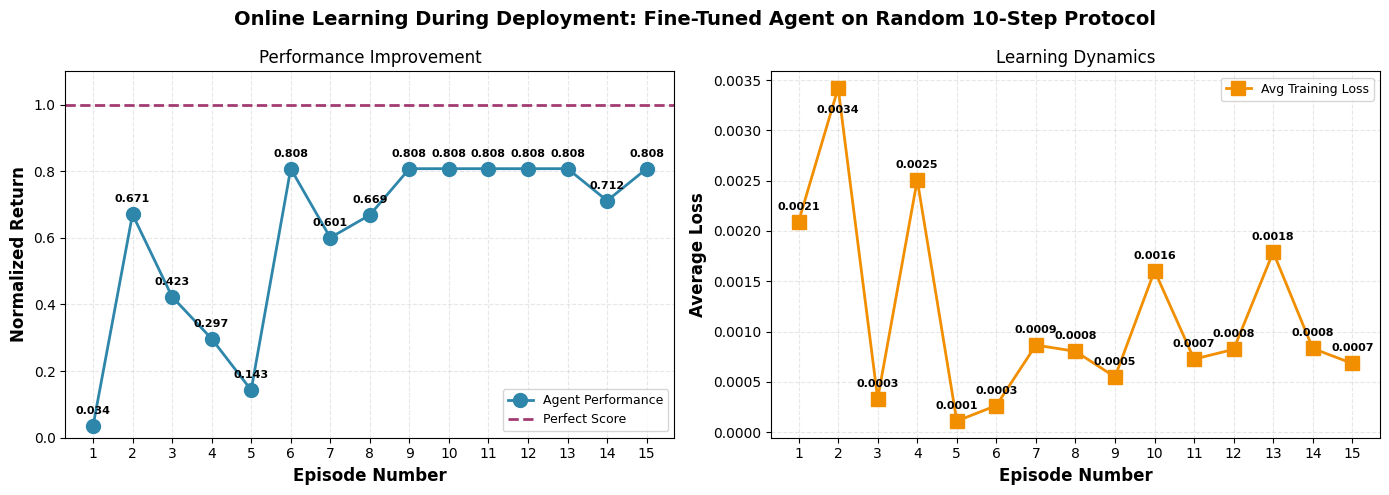

In [24]:
# Load fine-tuned agent
agent_finetuned = DRQNagent.load_complete(
    'models/DRQN_finetuned_length10.pkl',
    env_constructor=lambda: VoltageDistributionEnv(),
    feature_extractor_constructor=lambda obs_space: CustomFeatureExtractor(obs_space)
)

# Run experiment
results = test_cross_episode_adaptation(
    agent_finetuned,
    num_episodes=15,
)

# Plot visualization
plot_cross_episode_learning(
    results,
    save_path='models/plots/cross_episode_learning_improved.png'
)